In [1]:
import pandas as pd
import arivale_data_interface as adi
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# apply settings so the lib knows where the data is
adi.apply_isb_config()
from regression_functions import *

In [2]:
abx_covar = pd.read_csv("data/abx_recency_covariates_all.csv")
abx_covar.sort_values(by='days_in_program')

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,abx_recency,...,age,BMI_CALC,hx_t2dm,hx_gestational,gluc_dysreg,eGFR,centered_eGFR,centered_BMI,abx_recency_three,abx_recency_twelve
0,01071494,-0.216793,-0.110133,-0.088564,0.055447,0.006009,-40.0,No,No,none,...,49.0,30.598898,No,No,0,86.366123,-10.582038,2.736353,0,0
1,01568974,-0.149388,0.030381,0.617446,0.176120,0.042827,-7.0,No,No,twelve,...,46.0,35.662071,No,No,0,115.435836,18.487675,7.799525,0,1
2,01092042,-0.503311,-0.208429,-0.160230,-0.046219,0.061394,-7.0,No,No,none,...,54.0,19.483497,No,No,0,103.067192,6.119031,-8.379048,0,0
3,01601230,0.062362,-0.028922,-0.034839,0.086872,0.029430,-5.0,No,No,none,...,45.0,26.120098,No,No,0,88.199673,-8.748488,-1.742448,0,0
4,01684342,0.063423,-0.019438,-0.035673,-0.008457,0.001391,-5.0,No,No,none,...,32.0,22.668163,No,No,0,96.720816,-0.227344,-5.194382,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2661,01181682,0.058783,-0.010586,-0.012099,-0.051793,0.031362,629.0,No,Yes,twelve,...,49.0,24.676735,No,No,0,70.589153,-26.359008,-3.185811,0,1
2662,01201199,0.065988,-0.013680,-0.050926,0.044681,0.035107,712.0,No,No,three,...,42.0,32.413454,No,No,0,98.708674,1.760513,4.550909,1,0
2663,01440344,-0.490879,-0.196570,-0.115884,-0.019040,0.133794,731.0,No,Yes,three,...,47.0,23.957596,No,No,0,100.360100,3.411939,-3.904949,1,0
2664,01382823,0.065718,-0.021335,-0.035135,0.089997,0.031969,752.0,No,No,three,...,47.0,30.724246,No,No,0,107.280676,10.332515,2.861700,1,0


In [3]:
proteomics = adi.get_snapshot('proteomics_corrected').sort_values(by="days_in_program")
proteomics.columns = proteomics.columns.str.replace(',', '_')
proteomics.columns = proteomics.columns.str.replace('-', '_')
proteomics.days_in_program = proteomics.days_in_program.astype("float64")

In [4]:
proteomic_features = proteomics.columns[21:]
len(proteomic_features)

1195

In [5]:
proteomics.set_index(["public_client_id","days_in_program"], inplace = True)

In [6]:
proteomics = proteomics.iloc[:, 19:]

In [7]:
proteomics.reset_index(inplace=True)

In [8]:
proteomics_merged = pd.merge_asof(
    abx_covar.sort_values(by='days_in_program'), proteomics.sort_values(by='days_in_program'), 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest", 
    tolerance=30.0).dropna(subset=proteomic_features, how="all")
proteomics_merged

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,abx_recency,...,ONC3_Q9NTU7,ONC3_Q9P1Z2,ONC3_Q9UDT6,ONC3_Q9UHD8,ONC3_Q9UJY5,ONC3_Q9UMF0,ONC3_Q9Y2B0,ONC3_Q9Y5K2,ONC3_Q9Y5K8,ONC3_Q9Y644
1,01568974,-0.149388,0.030381,0.617446,0.176120,0.042827,-7.0,No,No,twelve,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01092042,-0.503311,-0.208429,-0.160230,-0.046219,0.061394,-7.0,No,No,none,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,01601230,0.062362,-0.028922,-0.034839,0.086872,0.029430,-5.0,No,No,none,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,01684342,0.063423,-0.019438,-0.035673,-0.008457,0.001391,-5.0,No,No,none,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,01324699,0.059337,-0.024547,-0.040044,0.094414,0.034026,-2.0,No,No,three,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2653,01726684,0.063963,-0.027301,-0.038506,0.085400,0.007325,408.0,No,Yes,three,...,3.036465,6.889535,5.80554,-0.072575,0.27961,5.17333,-2.01305,3.625465,-0.24199,1.339505
2658,01041538,0.029160,0.027134,0.102529,-0.517381,-0.033178,499.0,No,Yes,twelve,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2659,QIRL,0.066072,-0.023644,-0.040810,0.072321,0.034344,553.0,No,No,none,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2660,01232614,0.061376,-0.012418,-0.018141,0.031564,0.021440,593.0,No,No,twelve,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
len(proteomics_merged.columns[21:]) # looks like none dropped

1195

In [14]:
bad = proteomics_merged[proteomic_features].isnull().sum() / proteomics_merged.shape[0] > 0.30
proteomic_features = bad[~bad].index
proteomics_merged = proteomics_merged.drop(columns=bad[bad].index)
proteomics_merged.shape

(2255, 295)

In [15]:
# Total of 274 features
proteomic_features = proteomics_merged.columns[proteomics_merged.columns.isin(proteomic_features)] 

Index(['CVD2_O00182', 'CVD2_O00220', 'CVD2_O00253', 'CVD2_O14763',
       'CVD2_O14836', 'CVD2_O43915', 'CVD2_O94907', 'CVD2_P00797',
       'CVD2_P01127', 'CVD2_P01241',
       ...
       'INF_Q99748', 'INF_Q9BZW8', 'INF_Q9GZV9', 'INF_Q9H5V8', 'INF_Q9NRJ3',
       'INF_Q9NSA1', 'INF_Q9NYY1', 'INF_Q9NZQ7', 'INF_Q9P0M4', 'INF_Q9UHF4'],
      dtype='object', length=274)

In [19]:
# proteomic_features.tolist() # all CVDII, CVDIII, or INF

<Axes: >

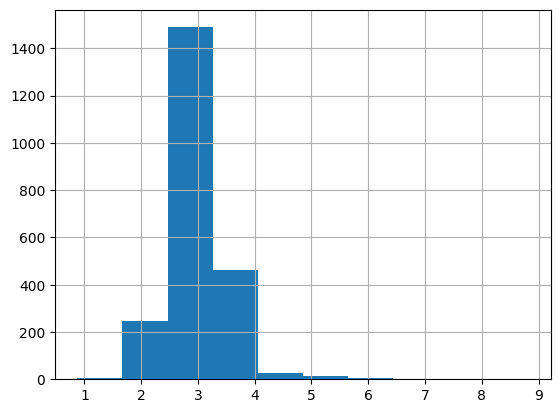

In [31]:
proteomics_merged['INF_Q9GZV9'].hist()

In [21]:
formula_prot = ("{feature} ~ C(sex) + age + BMI_CALC + C(abx_recency_three) + " 
               "C(abx_recency_twelve) + C(meds_cholesterol) + C(meds_blood_sugar) +"
               "PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR")
abx_term_three = "C(abx_recency_three)[T.1]"
abx_term_twelve = "C(abx_recency_twelve)[T.1]"

In [22]:
tests_threemo = run_tests(proteomic_features, proteomics_merged, formula_prot, abx_term_three)

Output()

In [24]:
sig_three = tests_threemo[tests_threemo["q"]<0.1].sort_values(by='q')
sig_three

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q


In [25]:
tests_twelvemo = run_tests(proteomic_features, proteomics_merged, formula_prot, abx_term_twelve)

Output()

In [26]:
sig_twelve = tests_twelvemo[tests_twelvemo["q"]<0.1].sort_values(by='q')
sig_twelve

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q


In [28]:
# For supplement:
tests_threemo.to_csv("data/proteomics_regressions_all_three.csv", index=False)
tests_twelvemo.to_csv("data/proteomics_regressions_all_twelve.csv", index=False)